# 07 · Modelo de LGD (pérdida en caso de impago)

**Objetivo:** encontrar el mejor modelo para estimar la **LGD**: la **fracción de la deuda pendiente que no se recupera** (notebook 04, D4). Va de 0 a 1, tiene media 0,87 y está muy concentrada: uno de cada cinco impagos la tiene en 1. Se entrena con los 65.836 préstamos impagados con deuda pendiente.

1. Fijar el listón: predicciones **sin modelo** (la media, la mediana y la mediana de cada plazo).
2. Elegir la **métrica** con la que se compara: la LGD entra en la pérdida esperada (PD × EAD × LGD), así que importa acertar la **media**.
3. Hacer una **búsqueda en rejilla** (`GridSearchCV`) que compara a la vez **tipos de modelo** (sin modelo, regresión lineal Ridge y *gradient boosting*) y sus **hiperparámetros**.
4. Elegir el modelo con la misma regla que en la PD (notebook 05), analizarlo y guardarlo.

**Cómo se trabaja:** igual que en los notebooks anteriores (observación → decisión → aplicación). El *pipeline* (con la preparación de `04_scripts/preparacion.py`), las particiones y la regla de elección son los mismos que en el notebook 05, para que los tres modelos se construyan igual.

> **Regla general:** el conjunto de **validación** no se toca; todas las comparaciones se hacen con validación cruzada dentro de entrenamiento.

<a id="s0"></a>

## Registro de decisiones

| # | Tema | Decisión | Motivo principal |
|---|---|---|---|
| D1 | Listón | Media global (RMSE 0,1478) | Sin sesgo; el plazo no cambia la LGD (0,869 con 36 cuotas y 0,868 con 60) |
| D2 | Métrica | RMSE para elegir; MAE y sesgo como control | La pérdida esperada necesita la LGD **media**, y el RMSE premia acertar la media (el MAE, la mediana) |
| D3 | Búsqueda | `GridSearchCV` con 2 modelos sin variables, 5 Ridge y 24 *gradient boosting* | Compara familias de modelo e hiperparámetros con las mismas particiones |
| D4 | Elección | **Sin modelo:** LGD = media de entrenamiento (0,869) para todos los préstamos | Ningún modelo con variables mejora a la media más que el azar de las particiones (regla de un error estándar) |
| D5 | Guardado | `05_modelos/modelo_lgd.pkl` con `cloudpickle` | La validación final y la API cargan el mismo objeto, sin necesitar `preparacion.py` |

## Índice

- [Registro de decisiones](#s0)
- [1 · Importar librerías](#s1)
- [2 · Cargar los datos](#s2)
- [3 · Listón: predicciones sin modelo (D1)](#s3)
- [4 · Métrica: ¿acertar la media o la mediana? (D2)](#s4)
- [5 · Pipeline y validación cruzada](#s5)
- [6 · Búsqueda del mejor modelo (D3)](#s6)
  - [6.1 · Resultados de la búsqueda](#s6-1)
  - [6.2 · RMSE frente a MAE](#s6-2)
- [7 · Elección del modelo (D4)](#s7)
- [8 · Análisis del modelo elegido](#s8)
  - [8.1 · Error frente al listón](#s8-1)
  - [8.2 · ¿Separa préstamos con LGD alta y baja?](#s8-2)
  - [8.3 · Importancia de las variables](#s8-3)
- [9 · Entrenar y guardar el modelo final (D5)](#s9)
- [10 · Resumen y próximos pasos](#s10)

> Cada sección empieza con una **franja azul**. Debajo de cada resultado hay una explicación de **qué se hace** y **qué se observa**.

<a id="s1"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">1 · IMPORTAR LIBRERÍAS</span>

</div>

In [1]:
# --- Librerías generales ----------------------------------------------------
from pathlib import Path          # rutas de archivos independientes del sistema operativo
import sys                        # añadir la carpeta 04_scripts a las rutas de Python
import time                       # medir cuánto tarda la búsqueda
import tempfile, shutil           # carpeta temporal para la caché del pipeline (y borrarla al final)
import warnings                   # silenciar avisos repetidos
import cloudpickle                # guardar el modelo entrenado junto con el código de preparacion.py
import numpy as np                # cálculo numérico
import pandas as pd               # manejo de tablas (DataFrames)
import matplotlib.pyplot as plt   # gráficos
import seaborn as sns             # gráficos estadísticos sobre matplotlib
import sklearn                    # para guardar la versión con el modelo

# --- Preparación de los datos (04_scripts/preparacion.py) --------------------
sys.path.insert(0, '../../04_scripts')   # la carpeta del módulo, relativa a 03_notebooks/es
import preparacion                       # el módulo completo (se necesita para guardarlo con el modelo)
from preparacion import (PreparacionScoring,   # transformador: limpieza, imputación, variables nuevas, recortes y logaritmos
                         preparar_conjunto,    # población del modelo y objetivos (impago, EAD, LGD)
                         COLUMNAS_ENTRADA,     # columnas originales que recibe el pipeline
                         CATEGORICAS, NUMERICAS)  # variables que salen de la preparación

# --- Preprocesado y pipeline -------------------------------------------------
from sklearn.compose import ColumnTransformer                    # tratar distinto cada grupo de columnas
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # codificar categóricas y estandarizar numéricas
from sklearn.pipeline import Pipeline                            # encadenar preprocesado y modelo
from sklearn.base import clone                                   # copia sin entrenar de un modelo

# --- Modelos -----------------------------------------------------------------
from sklearn.dummy import DummyRegressor                         # "modelo" sin variables: siempre la media o la mediana
from sklearn.linear_model import Ridge                           # regresión lineal con regularización L2
from sklearn.ensemble import HistGradientBoostingRegressor       # gradient boosting por histogramas

# --- Validación, búsqueda y métricas -------------------------------------------
from sklearn.model_selection import KFold, GridSearchCV, cross_val_predict
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.inspection import permutation_importance

# --- Opciones de visualización ------------------------------------------------
pd.set_option('display.float_format', lambda x: '%.4f' % x)  # 4 decimales: las diferencias entre modelos son pequeñas
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 120)                   # ver los hiperparámetros completos
sns.set_theme(style='whitegrid')
warnings.filterwarnings('ignore', category=UserWarning)      # avisos de categorías desconocidas en las particiones
warnings.filterwarnings('ignore', category=FutureWarning)

print(f"✅ Librerías importadas correctamente (scikit-learn {sklearn.__version__})")

✅ Librerías importadas correctamente (scikit-learn 1.9.1)


**Qué se hace:** se importan las librerías: preprocesado y *pipeline*, los tres tipos de modelo que se comparan, las herramientas de validación, búsqueda y métricas, y el módulo `04_scripts/preparacion.py` (igual que en el notebook 05).

**Qué se observa:** el mensaje confirma que todo está instalado y muestra la versión de `scikit-learn`, que se guarda con el modelo.

<a id="s2"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">2 · CARGAR LOS DATOS</span>

</div>

In [2]:
# Rutas de entrada y salida (relativas a la carpeta de este notebook: 03_notebooks/es)
RUTA_DATOS = Path('../../02_datos/03_Entrenamiento')
RUTA_MODELOS = Path('../../05_modelos')

# Conjunto de entrenamiento ORIGINAL con la población del modelo y los objetivos (preparar_conjunto)
df = preparar_conjunto(pd.read_pickle(RUTA_DATOS / 'train.pkl'))
df = df[df['lgd'].notna()]   # solo los impagados con deuda pendiente (LGD no nula)

# Variables del modelo tras la preparación: las 15 de la PD más el importe del préstamo ('principal')
NUMERICAS_MODELO = NUMERICAS + ['principal']
VARIABLES = CATEGORICAS + NUMERICAS_MODELO

# X = columnas originales que necesita la preparación · y = objetivo (LGD, entre 0 y 1)
# La limpieza, las imputaciones y las transformaciones las hace el primer paso del pipeline (sección 5)
X = df[COLUMNAS_ENTRADA]
y = df['lgd']

print(f"Préstamos: {X.shape[0]:,} · Columnas de entrada: {X.shape[1]}")
print(f"Variables tras la preparación: {len(VARIABLES)} ({len(CATEGORICAS)} categóricas y {len(NUMERICAS_MODELO)} numéricas)")
print(f"LGD: media {y.mean():.4f} · mediana {y.median():.4f} · desviación típica {y.std():.4f}")

Préstamos: 65,836 · Columnas de entrada: 19
Variables tras la preparación: 16 (4 categóricas y 12 numéricas)
LGD: media 0.8691 · mediana 0.8945 · desviación típica 0.1478


**Qué se hace:** se carga el conjunto de entrenamiento **original**; `preparar_conjunto()` quita las viviendas fuera de la población y calcula la LGD, y se quedan solo los impagados con deuda pendiente (LGD no nula). `X` son las 19 columnas originales que necesita la preparación. A las 15 variables de la PD se añade el importe del préstamo (`principal`), decidido en el notebook 04 (D12).

**Qué se observa:** **65.836 impagados** con deuda pendiente (los mismos que el tablón del notebook 04) y 16 variables tras la preparación. La LGD tiene media **0,869**, mediana **0,895** y una desviación típica de solo **0,148**: casi todos los impagos pierden entre el 80 % y el 100 % de la deuda.

<a id="s3"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">3 · LISTÓN: PREDICCIONES SIN MODELO (D1)</span>

</div>

Antes de buscar un modelo hay que saber **cuánto se equivoca no tener modelo**. Se prueban cuatro predicciones sencillas, calculadas con la parte de entrenamiento de cada partición y evaluadas en la otra (igual que un modelo):
- **Siempre la media** y **siempre la mediana** de la LGD.
- **La media** y **la mediana de cada plazo** (36 o 60 cuotas), la referencia del notebook 04 (D6).

Se miden tres errores:
- **MAE** (error absoluto medio): cuánto se equivoca de media cada predicción, en las mismas unidades que la LGD.
- **RMSE** (raíz del error cuadrático medio): como el MAE, pero los errores grandes pesan más.
- **Sesgo:** media predicha menos media real. Si no es 0, el modelo sobreestima (positivo) o subestima (negativo) la pérdida de la cartera.

In [3]:
# Particiones de la validación cruzada: 3 trozos con semilla fija (como en el notebook 05)
PARTICIONES = KFold(n_splits=3, shuffle=True, random_state=42)

def errores(y_real, prediccion):
    """MAE, RMSE y sesgo de una predicción."""
    return {'MAE': mean_absolute_error(y_real, prediccion),
            'RMSE': root_mean_squared_error(y_real, prediccion),
            'sesgo': np.mean(prediccion) - np.mean(y_real)}

def prediccion_sin_modelo(estadistico, por_plazo):
    """Predicción fuera de partición con la media o la mediana (global o de cada plazo)."""
    prediccion = pd.Series(np.nan, index=y.index)
    for entreno, evaluacion in PARTICIONES.split(X):
        if por_plazo:
            # Media / mediana de cada plazo aprendida en entrenamiento y aplicada a cada préstamo de evaluación
            # (num_cuotas está aún en su formato original, ' 36 months' / ' 60 months', que sirve igual para agrupar)
            valor_plazo = y.iloc[entreno].groupby(X['num_cuotas'].iloc[entreno]).agg(estadistico)
            prediccion.iloc[evaluacion] = X['num_cuotas'].iloc[evaluacion].map(valor_plazo).values
        else:
            prediccion.iloc[evaluacion] = y.iloc[entreno].agg(estadistico)
    return prediccion

liston = pd.DataFrame({
    f'{estadistico} {"de cada plazo" if por_plazo else "global"}': errores(y, prediccion_sin_modelo(estadistico, por_plazo))
    for estadistico in ['mean', 'median'] for por_plazo in [False, True]
}).T.rename(index=lambda s: s.replace('mean', 'media').replace('median', 'mediana'))
liston

,MAE,RMSE,sesgo
media global,0.0940,0.1478,-0.0000
media de cada plazo,0.0940,0.1478,-0.0000
mediana global,0.0928,0.1500,0.0254
mediana de cada plazo,0.0922,0.1499,0.0219


**Qué se hace:** MAE, RMSE y sesgo de las cuatro predicciones sin modelo, con validación cruzada.

**Qué se observa:** 
- **La media global y la de cada plazo dan exactamente lo mismo** (RMSE 0,1478): la LGD media es 0,869 con 36 cuotas y 0,868 con 60. El plazo, que era clave en la EAD, aquí no dice nada.
- **La mediana gana en MAE** (0,0922 la de cada plazo, el listón del notebook 04) pero tiene un **sesgo de +0,02 a +0,03**: sobreestimaría la pérdida.
- Como la LGD está tan concentrada, el error sin modelo ya es pequeño: un 0,148 de RMSE.

> **Decisión D1 · El listón es la media global de la LGD (RMSE 0,1478, sesgo 0).**
> - **Por qué la media:** por la métrica elegida en la sección 4 (D2).
> - **Por qué global y no de cada plazo:** dan lo mismo, y la global es más sencilla.
> - **El MAE de la mediana de cada plazo (0,092, notebook 04)** se sigue mostrando como referencia.

<a id="s4"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">4 · MÉTRICA: ¿ACERTAR LA MEDIA O LA MEDIANA? (D2)</span>

</div>

La tabla anterior muestra algo importante: **la mediana gana en MAE y la media gana en RMSE**. No es casualidad:
- El valor que hace **mínimo el MAE** es la **mediana**.
- El valor que hace **mínimo el RMSE** es la **media**.

¿Cuál interesa? La pérdida esperada de un préstamo es PD × EAD × LGD × importe, y la pérdida de la **cartera** es la suma de todas. Para que esa suma sea correcta, la LGD de cada préstamo tiene que ser correcta **en media**. Un modelo que acierta la mediana tendría un **sesgo** sistemático y sobreestimaría o subestimaría la pérdida de toda la cartera.

> **Decisión D2 · Elegir el modelo por RMSE; vigilar el MAE y el sesgo.**
> - **Por qué RMSE:** premia acertar la media, que es lo que necesita la pérdida esperada. El sesgo debe quedar cerca de 0.
> - **Qué cambia respecto al notebook 04 (D6):** allí se fijó el listón en MAE (0,092). Se sigue mostrando, pero no decide: un modelo puede bajar el MAE solo por acercarse a la mediana, a costa de sesgar la pérdida esperada.
> - **Alternativa descartada:** elegir por MAE. Llevaría a modelos que predicen la mediana (por ejemplo, el *gradient boosting* con pérdida absoluta de la sección 6).

<a id="s5"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">5 · PIPELINE Y VALIDACIÓN CRUZADA</span>

</div>

Se usa el **mismo *pipeline*** que en el notebook 05 (D2): la preparación (`PreparacionScoring`), *one-hot* para las categóricas y estandarización para las numéricas, seguidos del modelo, todo en un objeto. También se usa una **caché** para no repetir la preparación en cada combinación de la búsqueda. Las particiones (3, semilla 42) se definieron en la sección 3.

In [4]:
# Carpeta temporal para la caché de los pasos de preparación y preprocesado (se borra en la sección 9)
CACHE = tempfile.mkdtemp(prefix='cache_' + y.name + '_')

def crear_pipeline(modelo, categoricas=CATEGORICAS, numericas=NUMERICAS_MODELO, parametros=None, cache=CACHE):
    """Devuelve un pipeline nuevo: preparación (preparacion.py) + preprocesado (one-hot + estandarización) + modelo.
    Si se pasan 'parametros' (por ejemplo, los de una combinación de la búsqueda), se aplican al pipeline.
    'cache' es la carpeta donde se reutilizan los pasos ya calculados (None = sin caché, para el modelo final)."""
    preprocesado = ColumnTransformer([
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas),  # una columna por categoría
        ('numericas', StandardScaler(), numericas),                            # media 0 y desviación 1
    ])
    pipeline = Pipeline([
        ('preparacion', PreparacionScoring()),   # columnas originales -> 15 variables de la PD + principal
        ('preprocesado', preprocesado),
        ('modelo', modelo),
    ], memory=cache)
    if parametros is not None:
        pipeline.set_params(**parametros)
    return clone(pipeline)   # copia independiente: entrenar un pipeline no modifica a los demás

crear_pipeline(Ridge())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparacion', ...), ('preprocesado', ...), ...]"
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",'C:\\Users\\User\\AppDa...emp\\cache_lgd_jbnbt_d8'
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,percentil_recorte,0.999
,tope_consultas,4.0
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categoricas', ...), ('numericas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fi

**Qué se hace:** se define la función que construye el *pipeline* (igual que en el notebook 05) y se muestra con un Ridge de ejemplo.

**Qué se observa:** los tres pasos: la preparación, el `ColumnTransformer` con sus dos ramas y el modelo.

<a id="s6"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">6 · BÚSQUEDA DEL MEJOR MODELO (D3)</span>

</div>

Como en el notebook 05, la rejilla incluye el **tipo de modelo** como una opción más:

**1. Sin variables** (`DummyRegressor`, 2 combinaciones): siempre la media o siempre la mediana. Están en la búsqueda para que un modelo con variables tenga que **ganarles** con las mismas reglas.

**2. Ridge** (5 combinaciones): regresión lineal con regularización L2. `alpha` ∈ {0,1 · 1 · 10 · 100 · 1000} es la fuerza de la regularización (al revés que la `C` de la logística: más `alpha`, coeficientes más pequeños).

**3. *Gradient boosting*** (`HistGradientBoostingRegressor`, 24 combinaciones):
- `loss` ∈ {`squared_error`, `absolute_error`}: qué error minimiza al entrenar. El cuadrático apunta a la media; el absoluto, a la mediana (sección 4).
- `learning_rate` ∈ {0,05 · 0,1}, `max_leaf_nodes` ∈ {15 · 31 · 63} y `min_samples_leaf` ∈ {100 · 500}: igual que en el notebook 05.
- El número de árboles lo decide la **parada temprana**.

In [5]:
# Pipeline base: el paso 'modelo' se sustituye en cada combinación de la rejilla
pipeline_base = crear_pipeline(DummyRegressor())

# Rejilla: un diccionario por familia de modelo
REJILLA = [
    {   # 1. Sin variables: siempre la media o la mediana de entrenamiento
        'modelo': [DummyRegressor()],
        'modelo__strategy': ['mean', 'median'],
    },
    {   # 2. Regresión lineal con regularización L2
        'modelo': [Ridge()],
        'modelo__alpha': [0.1, 1, 10, 100, 1000],
    },
    {   # 3. Gradient boosting con parada temprana
        'modelo': [HistGradientBoostingRegressor(max_iter=1000, early_stopping=True, random_state=42)],
        'modelo__loss': ['squared_error', 'absolute_error'],
        'modelo__learning_rate': [0.05, 0.1],
        'modelo__max_leaf_nodes': [15, 31, 63],
        'modelo__min_samples_leaf': [100, 500],
    },
]

busqueda = GridSearchCV(
    pipeline_base,
    REJILLA,
    cv=PARTICIONES,
    # sklearn siempre maximiza, por eso los errores van con signo negativo
    scoring={'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error'},
    refit=False,              # solo compara; el modelo elegido se entrena después (sección 9)
    return_train_score=True,  # error también en entrenamiento, para ver el sobreajuste
    n_jobs=-1,                # usar todos los núcleos del procesador
)

inicio = time.time()
busqueda.fit(X, y)
print(f"✅ {len(busqueda.cv_results_['params'])} combinaciones × 3 particiones evaluadas en {(time.time() - inicio) / 60:.1f} minutos")

✅ 31 combinaciones × 3 particiones evaluadas en 4.3 minutos


**Qué se hace:** se define la rejilla con las tres familias y se lanza la búsqueda: 31 combinaciones × 3 particiones = 93 entrenamientos.

**Qué se observa:** las 93 evaluaciones tardan **unos 2 minutos** en este equipo (4 núcleos).

> **Decisión D3 · Una búsqueda con 2 modelos sin variables, 5 Ridge y 24 *gradient boosting*.**
> - **Por qué Ridge y no la regresión lineal simple:** con muchas columnas del *one-hot* la regularización evita coeficientes inestables; con `alpha` pequeño es casi igual a la lineal simple.
> - **Por qué incluir los modelos sin variables en la búsqueda:** así compiten con las mismas particiones y la misma regla de elección; si un modelo no les gana con claridad, no merece la pena.
> - **Alternativas descartadas:**
>   - **Regresión beta o logística fraccional:** pensadas para objetivos entre 0 y 1. Son el estándar académico para la LGD, pero `scikit-learn` no las incluye y no cambian el problema de fondo (sección 8).
>   - **Modelo en dos etapas** (primero "¿se recupera algo?", después "¿cuánto?"): es la alternativa más prometedora para la LGD, porque uno de cada cinco impagos tiene LGD = 1 (no se recupera nada) y 413 la tienen en 0. Queda como mejora futura: la sección 8 muestra que las variables de la solicitud apenas tienen información sobre la LGD, así que es poco probable que cambie mucho.

<a id="s6-1"></a>

### 6.1 · Resultados de la búsqueda

In [6]:
FAMILIAS = {'DummyRegressor': 'sin variables', 'Ridge': 'Ridge', 'HistGradientBoostingRegressor': 'gradient boosting'}
COMPLEJIDAD = {'sin variables': 0, 'Ridge': 1, 'gradient boosting': 2}

def resumen_busqueda(busqueda):
    """Convierte cv_results_ en una tabla legible: una fila por combinación, ordenada por RMSE."""
    r = pd.DataFrame(busqueda.cv_results_)
    tabla = pd.DataFrame({
        'familia': r['param_modelo'].apply(lambda m: FAMILIAS[type(m).__name__]),
        'hiperparametros': r['params'].apply(
            lambda p: ', '.join(f"{k.replace('modelo__', '')}={v}" for k, v in p.items() if k != 'modelo')),
        'RMSE': -r['mean_test_RMSE'],                 # se cambia el signo: más bajo es mejor
        'RMSE_std': r['std_test_RMSE'],               # variación entre las 3 particiones
        'RMSE_entrenamiento': -r['mean_train_RMSE'],  # para ver el sobreajuste
        'MAE': -r['mean_test_MAE'],
        'segundos': r['mean_fit_time'],
    })
    tabla['complejidad'] = tabla['familia'].map(COMPLEJIDAD)   # para la regla de elección (sección 7)
    tabla['indice'] = r.index                                  # posición en cv_results_
    return tabla.sort_values('RMSE').reset_index(drop=True)

resultados = resumen_busqueda(busqueda)
resultados.drop(columns=['complejidad', 'indice'])

,familia,hiperparametros,RMSE,RMSE_std,RMSE_entrenamiento,MAE,segundos
0,gradient boosting,"learning_rate=0.05, loss=squared_error, max_leaf_nodes=15, min_samples_leaf=500",0.1472,0.0014,0.1461,0.0941,32.7218
1,Ridge,alpha=1000,0.1472,0.0014,0.1471,0.0940,22.6610
2,Ridge,alpha=100,0.1472,0.0014,0.1471,0.0941,30.0004
3,Ridge,alpha=10,0.1472,0.0014,0.1471,0.0942,31.3892
4,Ridge,alpha=1,0.1473,0.0014,0.1471,0.0942,29.8216
5,Ridge,alpha=0.1,0.1473,0.0014,0.1471,0.0942,30.3491
6,gradient boosting,"learning_rate=0.05, loss=squared_error, max_leaf_nodes=15, min_samples_leaf=100",0.1473,0.0014,0.1461,0.0940,32.7124
7,gradient boosting,"learning_rate=0.05, loss=squared_error, max_leaf_nodes=31, min_samples_leaf=500",0.1473,0.0014,0.1460,0.0940,31.4653
8,gradient boosting,"learning_rate=0.1, loss=squared_error, max_leaf_nodes=15, min_samples_leaf=500",0.1473,0.0015,0.1460,0.0942,24.8082
9,gradient boosting,"learning_rate=0.05, loss=squared_error, max_leaf_nodes=31, min_samples_leaf=100",0.1473,0.0014,0.1455,0.0940,31.7054


**Qué se hace:** se resume la búsqueda en una tabla ordenada por RMSE (de mejor a peor), con su variación entre particiones, el RMSE en entrenamiento, el MAE y el tiempo.

**Qué se observa:**
- **Los 17 primeros** (*gradient boosting* con pérdida cuadrática y Ridge) están **prácticamente empatados** entre 0,1472 y 0,1474.
- **Predecir siempre la media** queda justo después, con **0,1478**: los modelos solo la mejoran en la **cuarta cifra decimal**.
- Los de **pérdida absoluta** tienen el mejor MAE (≈ 0,092) pero peor RMSE (≈ 0,149), y la mediana es la última.
- La **desviación típica entre particiones (0,0014)** es más del doble de la mejora de los modelos sobre la media (0,0006).

In [7]:
# Mejor combinación de cada familia, comparada con "siempre la media"
mejores_por_familia = resultados.groupby('familia').head(1).set_index('familia')
rmse_media = resultados.loc[resultados['hiperparametros'] == 'strategy=mean', 'RMSE'].iloc[0]
mejores_por_familia['mejora_RMSE_vs_media_%'] = 100 * (1 - mejores_por_familia['RMSE'] / rmse_media)
mejores_por_familia[['hiperparametros', 'RMSE', 'RMSE_std', 'MAE', 'mejora_RMSE_vs_media_%']]

,hiperparametros,RMSE,RMSE_std,MAE,mejora_RMSE_vs_media_%
familia,,,,,
gradient boosting,"learning_rate=0.05, loss=squared_error, max_leaf_nodes=15, min_samples_leaf=500",0.1472,0.0014,0.0941,0.3793
Ridge,alpha=1000,0.1472,0.0014,0.0940,0.3743
sin variables,strategy=mean,0.1478,0.0014,0.0940,0.0000


**Qué se hace:** la mejor combinación de cada familia y cuánto mejora el RMSE (en %) frente a predecir siempre la media.

**Qué se observa:** el mejor Ridge **solo mejora un 0,4 % el RMSE de predecir siempre la media** (el mejor *gradient boosting*, igual). Con las variables de la solicitud **no se puede predecir la LGD**: lo que se recupera de un impago depende de cosas que no se saben al conceder el préstamo (la gestión de cobro, la venta de la deuda, la situación del cliente al impagar).

<a id="s6-2"></a>

### 6.2 · RMSE frente a MAE

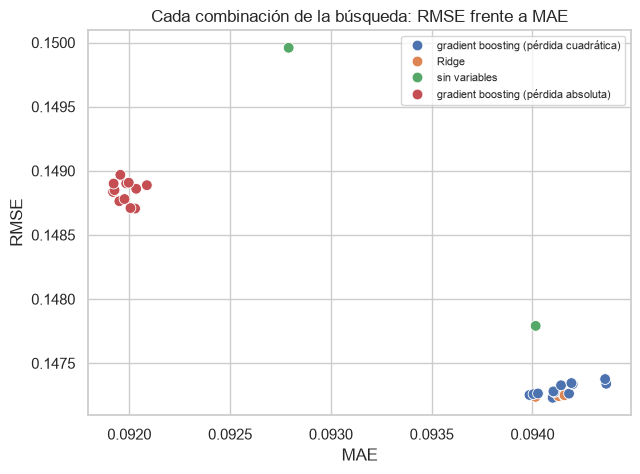

In [8]:
# Cada punto es una combinación de la búsqueda; los ejes muestran sus dos errores
fig, eje = plt.subplots(figsize=(7, 5))
resultados['grupo'] = resultados['familia'] + np.where(resultados['hiperparametros'].str.contains('absolute_error'), ' (pérdida absoluta)',
                                              np.where(resultados['hiperparametros'].str.contains('squared_error'), ' (pérdida cuadrática)', ''))
sns.scatterplot(data=resultados, x='MAE', y='RMSE', hue='grupo', s=60, ax=eje)
eje.set_title('Cada combinación de la búsqueda: RMSE frente a MAE')
eje.legend(fontsize=8)
plt.show()

**Qué se hace:** cada punto es una combinación de la búsqueda, situada según su MAE (horizontal) y su RMSE (vertical). Abajo a la izquierda es mejor en los dos.

**Qué se observa:** como en la EAD, hay dos grupos: los de pérdida cuadrática (y Ridge) abajo, con mejor RMSE, y los de pérdida absoluta a la izquierda, con mejor MAE. Pero aquí **todos los puntos están muy juntos**: ninguna combinación se separa de las demás.

<a id="s7"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">7 · ELECCIÓN DEL MODELO (D4)</span>

</div>

Se aplica la misma **regla de un error estándar** que en el notebook 05: entre los modelos cuyo RMSE está a menos de **un error estándar** del mejor (la desviación típica entre particiones dividida por √3), se elige el más sencillo: primero sin variables, después Ridge y, por último, *gradient boosting*.

In [9]:
# Umbral: RMSE del mejor más su error estándar (desviación típica entre particiones / √nº de particiones)
mejor = resultados.iloc[0]
error_estandar = mejor['RMSE_std'] / np.sqrt(PARTICIONES.get_n_splits())
umbral = mejor['RMSE'] + error_estandar

# Candidatos empatados con el mejor y, entre ellos, el más sencillo (y dentro de la familia, el de menor RMSE)
empatados = resultados[resultados['RMSE'] <= umbral]
elegido = empatados.sort_values(['complejidad', 'RMSE']).iloc[0]
PARAMETROS_ELEGIDO = busqueda.cv_results_['params'][elegido['indice']]

print(f"Mejor RMSE: {mejor['RMSE']:.4f} ({mejor['familia']}) · error estándar {error_estandar:.4f} → umbral {umbral:.4f}")
print(f"Empatados con el mejor: {len(empatados)} → {empatados['familia'].value_counts().to_dict()}")
print(f"Elegido: {elegido['familia']} · {elegido['hiperparametros']} · RMSE {elegido['RMSE']:.4f}")

Mejor RMSE: 0.1472 (gradient boosting) · error estándar 0.0008 → umbral 0.1481
Empatados con el mejor: 18 → {'gradient boosting': 12, 'Ridge': 5, 'sin variables': 1}
Elegido: sin variables · strategy=mean · RMSE 0.1478


**Qué se hace:** se calcula el umbral, se buscan los empatados con el mejor y se elige el más sencillo.

**Qué se observa:** el umbral es 0,1481 (0,1472 + 0,0008). **18 combinaciones están empatadas con el mejor**, entre ellas la media (0,1478). Como es la opción más sencilla, la regla la elige: **la LGD se estima con la media de entrenamiento**.

> **Decisión D4 · Estimar la LGD con la media de entrenamiento (0,869) para todos los préstamos.**
> - **Por qué:** el mejor modelo con variables mejora el RMSE un 0,4 %, menos que lo que varía el resultado de una partición a otra. Un modelo que no gana con claridad añade complejidad (y variables que pedir en la API) sin mejorar la pérdida esperada.
> - **Qué lo apoya:** en la sección 8 el mejor modelo de la búsqueda solo separa la LGD entre **0,84 y 0,89** del decil más bajo al más alto, y explica menos del 1 % de su variación.
> - **Es una práctica habitual:** en préstamos al consumo sin garantía muchas entidades usan una **LGD fija por segmento** en lugar de un modelo.
> - **Alternativas:**
>   - **Ridge** (`alpha` 1000): sería la opción si se quiere un modelo con variables, por ejemplo para que la demo responda a lo que escribe el usuario. La diferencia en pérdida esperada sería mínima.
>   - **Modelo en dos etapas** (sección 6, D3): mejora futura.

<a id="s8"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">8 · ANÁLISIS DEL MODELO ELEGIDO</span>

</div>

Como en el notebook 05, se usan **predicciones fuera de partición**: cada préstamo recibe la predicción del modelo entrenado sin él. Para comparar, se calculan también las del **mejor modelo de la búsqueda** (el primero de la tabla de la sección 6.1) y la de la media de cada plazo.

In [10]:
# Predicciones fuera de partición del elegido y del mejor de la búsqueda
pipeline_elegido = crear_pipeline(DummyRegressor(), parametros=PARAMETROS_ELEGIDO)
pipeline_mejor = crear_pipeline(DummyRegressor(), parametros=busqueda.cv_results_['params'][mejor['indice']])

predicciones = pd.DataFrame({
    'elegido': cross_val_predict(pipeline_elegido, X, y, cv=PARTICIONES, n_jobs=-1),
    'mejor de la búsqueda': cross_val_predict(pipeline_mejor, X, y, cv=PARTICIONES, n_jobs=-1),
    'media de cada plazo': prediccion_sin_modelo('mean', por_plazo=True).values,
}, index=y.index).clip(0, 1)   # la predicción se limita a 0–1, igual que se hará en la API

print("Rango de las predicciones del mejor de la búsqueda:",
      f"{predicciones['mejor de la búsqueda'].min():.3f} – {predicciones['mejor de la búsqueda'].max():.3f}")

Rango de las predicciones del mejor de la búsqueda: 0.808 – 0.926


**Qué se hace:** predicciones fuera de partición del modelo elegido, del mejor de la búsqueda y de la media de cada plazo, limitadas a 0–1.

**Qué se observa:** el elegido predice **0,869 para todos** (es la media). El mejor de la búsqueda solo se mueve entre **0,81 y 0,93**: incluso el mejor modelo apenas se separa de la media.

<a id="s8-1"></a>

### 8.1 · Error frente al listón

In [11]:
tabla_errores = pd.DataFrame({nombre: errores(y, prediccion) for nombre, prediccion in predicciones.items()}).T
tabla_errores['R2'] = 1 - tabla_errores['RMSE'] ** 2 / y.var(ddof=0)   # % de la varianza de la LGD/EAD que se explica
tabla_errores

,MAE,RMSE,sesgo,R2
elegido,0.0940,0.1478,-0.0000,-0.0000
mejor de la búsqueda,0.0941,0.1472,-0.0000,0.0075
media de cada plazo,0.0940,0.1478,-0.0000,-0.0000


**Qué se hace:** MAE, RMSE, sesgo y R² (qué parte de la variación de la LGD explica cada predicción) de las tres opciones.

**Qué se observa:** el mejor de la búsqueda baja el RMSE de **0,1478 a 0,1472** y explica el **0,8 %** de la variación de la LGD (R² 0,008). La media tiene R² 0 por definición. El MAE es igual en los tres (0,0940) y ninguno tiene sesgo.

<a id="s8-2"></a>

### 8.2 · ¿Separa préstamos con LGD alta y baja?

Aunque el error medio baje poco, un modelo puede ser útil si **ordena** bien: si los préstamos a los que predice más LGD tienen de verdad más LGD. Se agrupan en 10 tramos según la predicción del **mejor modelo de la búsqueda** y se compara la media predicha con la real.

,n,prediccion_media,real_media
decil,,,
1,6584,0.8417,0.8447
2,6584,0.8542,0.8579
3,6583,0.8605,0.8576
4,6584,0.8652,0.8666
5,6583,0.8690,0.8700
6,6584,0.8722,0.8721
7,6583,0.8750,0.8715
8,6584,0.8780,0.8773
9,6583,0.8819,0.8833


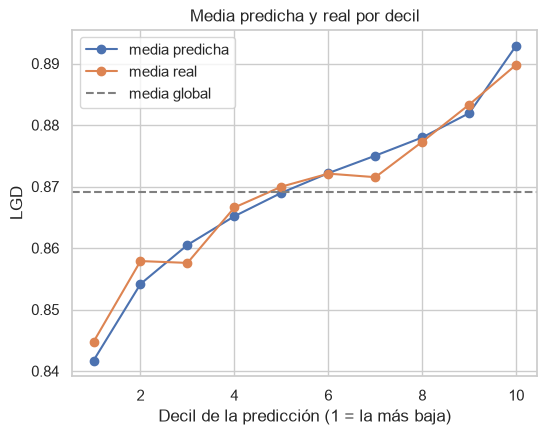

In [12]:
deciles = pd.qcut(predicciones['mejor de la búsqueda'].rank(method='first'), 10, labels=range(1, 11))
por_decil = pd.DataFrame({'prediccion': predicciones['mejor de la búsqueda'], 'real': y, 'decil': deciles}).groupby('decil', observed=True).agg(
    n=('real', 'size'), prediccion_media=('prediccion', 'mean'), real_media=('real', 'mean'))
display(por_decil)

fig, eje = plt.subplots(figsize=(6, 4.5))
eje.plot(por_decil.index.astype(int), por_decil['prediccion_media'], marker='o', label='media predicha')
eje.plot(por_decil.index.astype(int), por_decil['real_media'], marker='o', label='media real')
eje.axhline(y.mean(), color='grey', linestyle='--', label='media global')
eje.set_xlabel('Decil de la predicción (1 = la más baja)')
eje.set_ylabel(y.name.upper())
eje.set_title('Media predicha y real por decil')
eje.legend()
plt.show()

**Qué se hace:** media predicha y media real en cada decil de la predicción del mejor modelo de la búsqueda.

**Qué se observa:** incluso el mejor modelo de la búsqueda **casi no separa**: la LGD real va de **0,84** en el decil 1 a **0,89** en el decil 10. Es una diferencia de 5 puntos sobre una media de 87: para la pérdida esperada de un préstamo, cambiaría la LGD de 0,87 a, como mucho, 0,84 o 0,89.

<a id="s8-3"></a>

### 8.3 · Importancia de las variables

Importancia por permutación del **mejor modelo de la búsqueda** (como en el notebook 05): cuánto empeora el RMSE al desordenar cada una de las 16 **variables preparadas**. Se entrena con dos particiones y se mide en la tercera.

,aumento_RMSE,desviacion
ingresos,0.0006,0.0001
sector_empleo,0.0002,0.0000
vivienda,0.0001,0.0000
saldo_revolving,0.0001,0.0000
antiguedad_historial,0.0001,0.0000
antigüedad_empleo,0.0001,0.0000
fico,0.0000,0.0000
dti,0.0000,0.0000


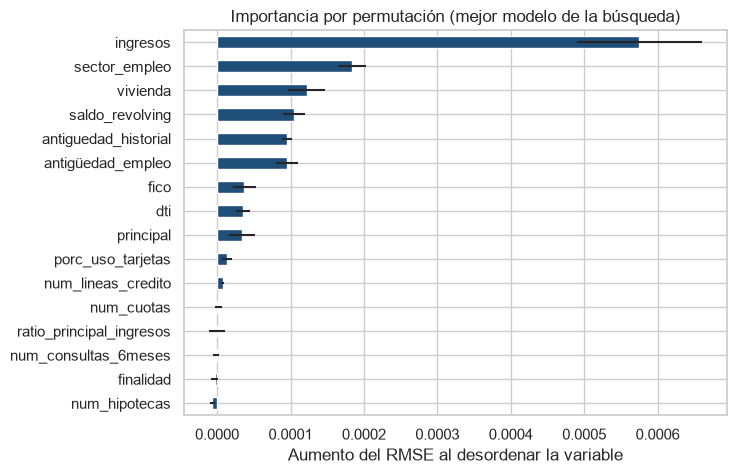

In [13]:
# Primera partición: entrenar con dos trozos y medir en el tercero
indices_entreno, indices_evaluacion = next(PARTICIONES.split(X))
modelo_particion = clone(pipeline_mejor).fit(X.iloc[indices_entreno], y.iloc[indices_entreno])

# El pipeline se divide en dos: [:1] = preparación · [1:] = preprocesado + modelo.
# Se prepara la parte de evaluación y se desordena cada variable preparada antes del preprocesado
evaluacion_preparada = modelo_particion[:1].transform(X.iloc[indices_evaluacion])[VARIABLES]
importancia = permutation_importance(modelo_particion[1:], evaluacion_preparada, y.iloc[indices_evaluacion],
                                     scoring='neg_root_mean_squared_error', n_repeats=3, random_state=42, n_jobs=-1)
tabla_importancia = pd.DataFrame({'aumento_RMSE': importancia.importances_mean, 'desviacion': importancia.importances_std},
                                 index=VARIABLES).sort_values('aumento_RMSE', ascending=False)
display(tabla_importancia.head(8))

fig, eje = plt.subplots(figsize=(7, 5))
tabla_importancia['aumento_RMSE'][::-1].plot.barh(xerr=tabla_importancia['desviacion'][::-1], ax=eje, color='#1f4e79')
eje.set_xlabel('Aumento del RMSE al desordenar la variable')
eje.set_title('Importancia por permutación (mejor modelo de la búsqueda)')
plt.show()

**Qué se hace:** caída del acierto (aumento del RMSE) al desordenar cada variable, en la tercera partición.

**Qué se observa:** ninguna variable importa: la más importante, `ingresos`, solo sube el RMSE en 0,0006 al desordenarla, y el resto en 0,0002 o menos. Es otra forma de ver que la LGD no depende de los datos de la solicitud.

<a id="s9"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">9 · ENTRENAR Y GUARDAR EL MODELO FINAL (D5)</span>

</div>

In [14]:
# Entrenar el pipeline elegido con TODOS los préstamos (sin caché: el modelo guardado no debe depender de ella)
modelo_final = crear_pipeline(DummyRegressor(), parametros=PARAMETROS_ELEGIDO, cache=None).fit(X, y)

# Paquete que se guarda: el modelo y todo lo necesario para usarlo y evaluarlo después
paquete = {
    'modelo': modelo_final,                          # pipeline completo (preparación + preprocesado + modelo)
    'columnas_entrada': COLUMNAS_ENTRADA,            # columnas originales que acepta el pipeline
    'variables': VARIABLES,                          # variables que usa el modelo tras la preparación
    'categoricas': CATEGORICAS,
    'numericas': NUMERICAS_MODELO,
    'familia': elegido['familia'],
    'hiperparametros': elegido['hiperparametros'],
    'recortar_0_1': True,                            # la predicción se limita a 0–1 al usarla
    'metricas_validacion_cruzada': tabla_errores.loc['elegido'].to_dict(),
    'liston': tabla_errores.loc['media de cada plazo'].to_dict(),
    'version_sklearn': sklearn.__version__,          # un modelo guardado solo es seguro con la misma versión
    'version_pandas': pd.__version__,
}

# cloudpickle guarda el CÓDIGO de preparacion.py dentro del archivo (como en el notebook 05)
cloudpickle.register_pickle_by_value(preparacion)
RUTA_MODELOS.mkdir(exist_ok=True)                    # crea 05_modelos/ si no existe
ARCHIVO_MODELO = RUTA_MODELOS / 'modelo_lgd.pkl'
with open(ARCHIVO_MODELO, 'wb') as archivo:
    cloudpickle.dump(paquete, archivo)

# Comprobación: se vuelve a cargar y predice lo mismo
with open(ARCHIVO_MODELO, 'rb') as archivo:
    recargado = cloudpickle.load(archivo)
assert np.allclose(recargado['modelo'].predict(X.head(1000)), modelo_final.predict(X.head(1000)))
print(f"✅ modelo_lgd.pkl guardado en {RUTA_MODELOS} · {paquete['familia']} ({paquete['hiperparametros']})")
print({k: round(v, 4) for k, v in paquete['metricas_validacion_cruzada'].items()})

# La caché de la búsqueda ya no hace falta: se borra la carpeta temporal
shutil.rmtree(CACHE, ignore_errors=True)

✅ modelo_lgd.pkl guardado en ..\..\05_modelos · sin variables (strategy=mean)
{'MAE': 0.094, 'RMSE': 0.1478, 'sesgo': -0.0, 'R2': -0.0}


**Qué se hace:** se entrena el *pipeline* elegido con todos los préstamos y se guarda con sus metadatos, igual que la PD. Se comprueba que el archivo guardado predice lo mismo y se borra la caché.

**Qué se observa:** el "modelo" queda en `05_modelos/modelo_lgd.pkl`: un *pipeline* que devuelve siempre 0,869. Su RMSE es 0,1478 y su sesgo 0 en validación cruzada.

> **Decisión D5 · Guardar el modelo en `05_modelos/modelo_lgd.pkl` con `cloudpickle` y el mismo formato de paquete que la PD.**
> - **Por qué el mismo formato:** la validación final y la API cargan los tres modelos de la misma forma, sin casos especiales. Aunque el elegido sea la media, se guarda como un *pipeline* más; así, si en el futuro se sustituye por un modelo con variables, ni la validación ni la API tienen que cambiar.

<a id="s10"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">10 · RESUMEN Y PRÓXIMOS PASOS</span>

</div>

**Qué se ha hecho** (detalle en el registro de decisiones del principio):

| Bloque | Decisiones | Resultado |
|---|---|---|
| **Listón** | D1 | Media global: RMSE 0,1478, sin sesgo |
| **Métrica** | D2 | RMSE, porque la pérdida esperada necesita la LGD media |
| **Búsqueda** | D3 | 31 combinaciones en unos 2 minutos, con la preparación dentro del *pipeline* |
| **Elección** | D4 | **Sin modelo:** LGD = 0,869 para todos |
| **Guardado** | D5 | `05_modelos/modelo_lgd.pkl` (con `cloudpickle`) |

**Hallazgos principales:**
- **La LGD no se puede predecir con los datos de la solicitud.** El mejor modelo mejora el RMSE un 0,4 % y explica menos del 1 % de su variación; ninguna variable importa.
- La pérdida es **alta y estable**: de media se pierde el 87 % de la deuda pendiente, sin diferencias por plazo ni por año (notebook 04, D5).
- La regla de elección prefiere la **media**: más sencilla e igual de buena. Ridge es la alternativa si se quiere un modelo con variables.

**Próximos pasos:**
1. **08 · Validación final:** aplicar los tres modelos guardados al conjunto de validación y evaluar la PD, la EAD, la LGD y la pérdida esperada juntas.
2. **Nueva API** con los tres modelos.